# Single-input calibration: five regression and classification horizons
Each calibrator maps the frozen compact model output to actual Y. Methods: increasing isotonic (clipped outside fitted range), linear, quadratic/square (degree 2), cubic (degree 3). “Square” and “quadratic” mean the same degree mathematically; the fourth distinct method follows the earlier cubic experiment. Regression X/Y are THB MA5 predictions/actuals. Classification X is predicted probability and Y is the binary outcome. Polynomial classification outputs are clipped to [1e-6,1−1e-6] for valid probabilities; raw out-of-range rates are reported.

**Protocol:** TRAIN fits the base models. Earlier half of TEST fits calibrators; labels must mature before the split boundary. Skip 30 full context bars before later TEST validation. Select the regression calibrator by minimum later-TEST RMSE (all four methods remain visible); keep all four classifiers. OOT is scored after regression selection. No OOT-based choice. TRAIN calibration scores are retrospective backcasts using later-fitted parameters. OOT has been viewed in earlier research and is not pristine.


## Load frozen models and audit dates
Key: calibrator fit labels mature before validation starts. The full TEST set mixes calibration fit and validation, so use CAL_VALID for comparison.

In [1]:
from pathlib import Path
import pickle, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
from IPython.display import display
P=Path.cwd(); ROOT=P.parent; BASE=ROOT.parent
D=pd.read_csv(BASE/'Dataset_X_y.csv.gz',low_memory=False)
t=pd.to_datetime(D.decision_at,utc=True)
schedule=pd.read_csv(BASE/'Schedule.csv')
ids={r.partition:np.flatnonzero(t.between(pd.Timestamp(r.first),pd.Timestamp(r.last)) & D.eligible) for r in schedule.itertuples()}
test=ids['TEST']; split=int(len(test)*.5); boundary=test[split]
fit=test[:split]; fit=fit[(t.iloc[fit]+pd.Timedelta(minutes=75)<t.iloc[boundary]).to_numpy()]
validation=test[test>=boundary+30]
sets={**ids,'CAL_FIT':fit,'CAL_VALID':validation}
assert t.iloc[fit[-1]]+pd.Timedelta(minutes=75)<t.iloc[boundary]
assert validation[0]>=boundary+30
records=[]; deciles=[];parameters=[];selections=[]
def base_prediction(h,task,ix):
    b=pickle.load((ROOT/f'h{h}_{task}_compact.pkl').open('rb'))
    z=D.loc[ix,b['feature_names']].replace([np.inf,-np.inf],np.nan).fillna(b['medians']).to_numpy(float)
    z=(z-np.asarray(b['means']))/np.asarray(b['scales'])
    if task=='classification': return b['model'].predict_proba(z)[:,1]
    return D.loc[ix,f'baseline_h{h}'].to_numpy()+D.close.iloc[ix].to_numpy()*(b['model'].predict(z)*b['target_scale']+b['target_mean'])
def apply(model,method,x):
    return model.predict(x if method=='isotonic' else x.reshape(-1,1))
def ece(y,p,edges):
    group=np.searchsorted(edges,p,side='left');result=0.;rows=[]
    for k in range(len(edges)+1):
        take=group==k;n=int(take.sum())
        mp=float(p[take].mean()) if n else np.nan;rate=float(y[take].mean()) if n else np.nan
        if n: result+=n/len(y)*abs(mp-rate)
        rows.append(dict(bin=k+1,n=n,mean_probability=mp,observed_rate=rate))
    return result,rows
split_table=pd.DataFrame([dict(set=name,rows=len(ix),first_Bangkok=str(t.iloc[ix[0]].tz_convert('Asia/Bangkok')),last_Bangkok=str(t.iloc[ix[-1]].tz_convert('Asia/Bangkok'))) for name,ix in sets.items()])
split_table.to_csv(P/'split_audit.csv',index=False)
display(split_table)


,set,rows,first_Bangkok,last_Bangkok
0,TRAIN,24194,2025-01-01 01:15:00+07:00,2026-03-06 16:30:00+07:00
1,TEST,10372,2026-03-06 18:00:00+07:00,2026-09-05 02:45:00+07:00
2,OOT,3629,2026-09-07 07:30:00+07:00,2026-11-07 03:45:00+07:00
3,CAL_FIT,5181,2026-03-06 18:00:00+07:00,2026-06-08 08:45:00+07:00
4,CAL_VALID,5156,2026-06-08 17:45:00+07:00,2026-09-05 02:45:00+07:00


## Horizon 1: 15 minutes
Key: four single-input mappings are fitted on CAL_FIT. Regression selection uses CAL_VALID RMSE. Classification retains every mapping; clipped polynomial probabilities and out-of-range rates must be reviewed. TRAIN curves use later-fitted calibration parameters retrospectively.

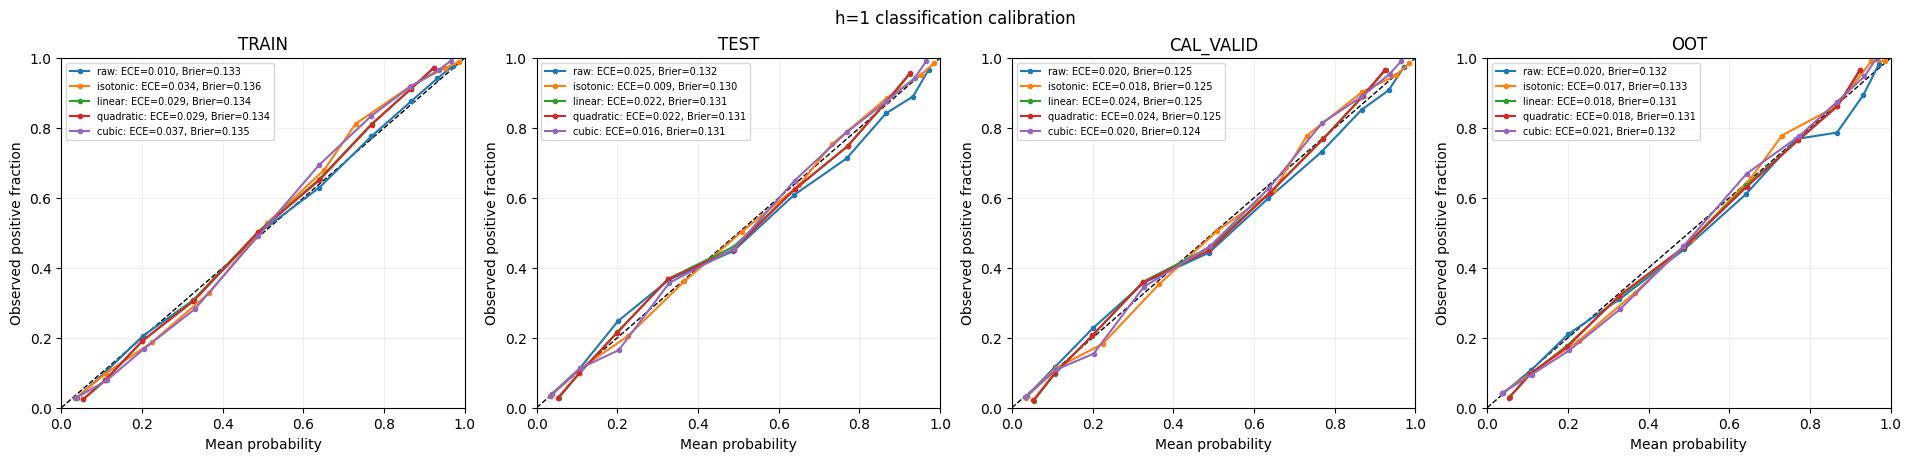

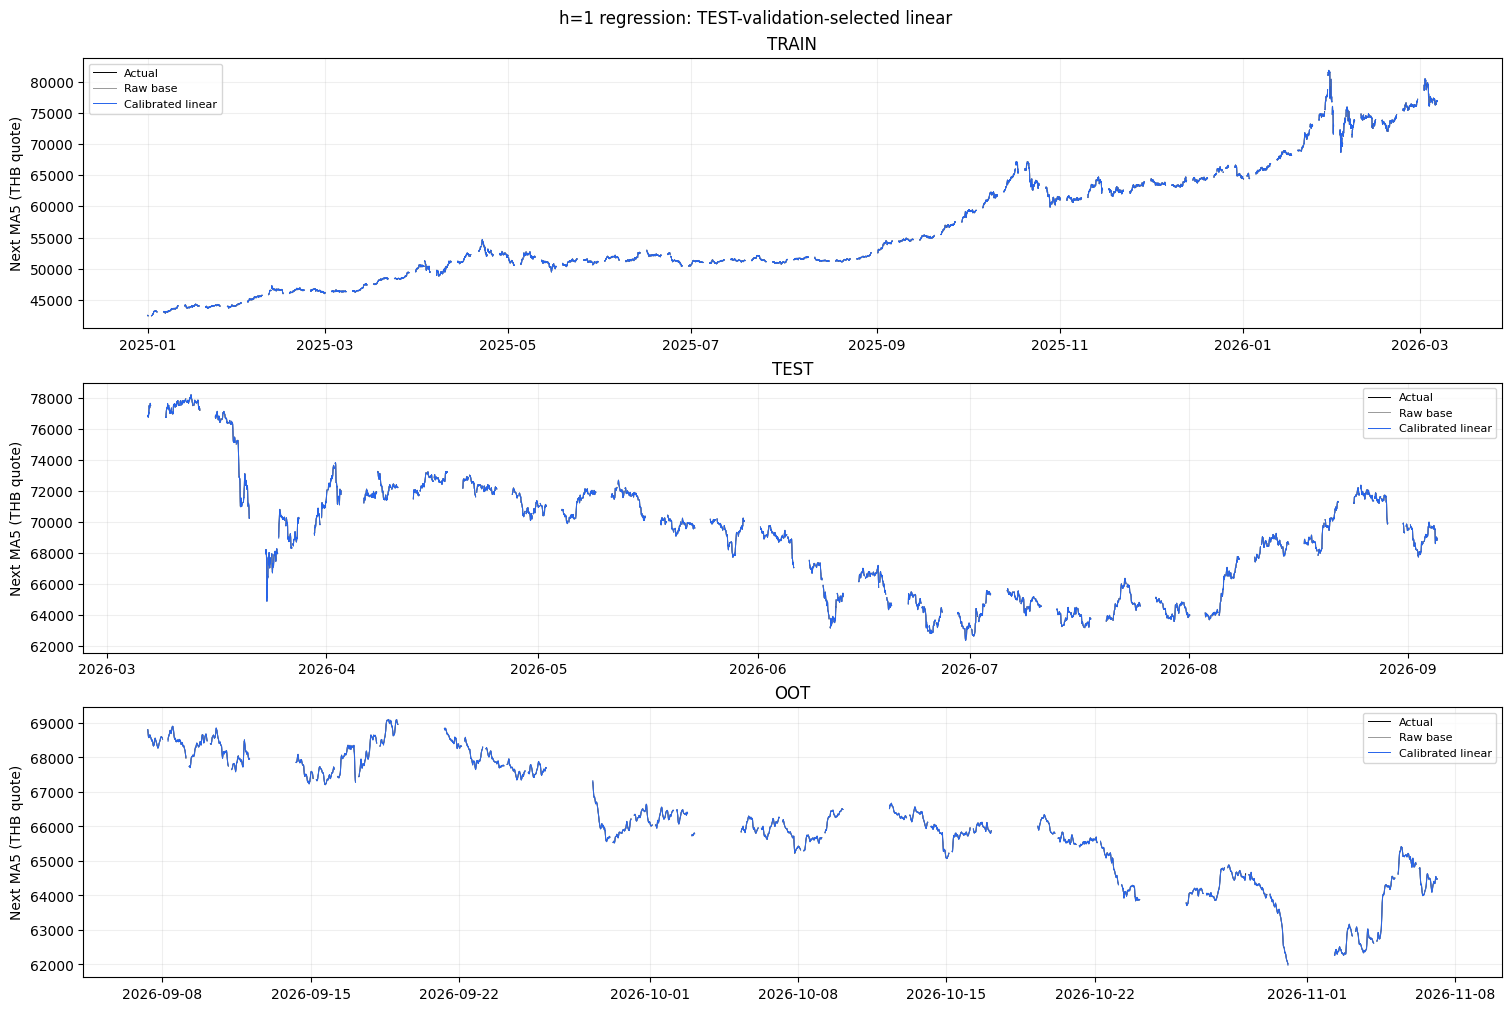

,horizon,task,partition,method,n,RMSE,MAE,Brier,ECE,accuracy,log_loss,outside_probability_range
10,1,regression,OOT,raw,3629,14.641214,10.536154,NaN,NaN,NaN,NaN,NaN
11,1,regression,OOT,isotonic,3629,729.585807,333.797528,NaN,NaN,NaN,NaN,NaN
12,1,regression,OOT,linear,3629,14.633771,10.535455,NaN,NaN,NaN,NaN,NaN
13,1,regression,OOT,quadratic,3629,15.083488,11.054050,NaN,NaN,NaN,NaN,NaN
14,1,regression,OOT,cubic,3629,19.497329,14.882304,NaN,NaN,NaN,NaN,NaN
15,1,regression,CAL_FIT,raw,5181,22.667630,14.525826,NaN,NaN,NaN,NaN,NaN
16,1,regression,CAL_FIT,isotonic,5181,17.835822,11.936435,NaN,NaN,NaN,NaN,NaN
17,1,regression,CAL_FIT,linear,5181,22.647748,14.513814,NaN,NaN,NaN,NaN,NaN
18,1,regression,CAL_FIT,quadratic,5181,22.640370,14.517692,NaN,NaN,NaN,NaN,NaN
19,1,regression,CAL_FIT,cubic,5181,22.630373,14.515490,NaN,NaN,NaN,NaN,NaN


In [2]:
h=1
# Fit only on earlier TEST labels. Numerical scaling uses CAL_FIT predictions only.
models={}; data={}; predictions={}
for task in ['regression','classification']:
    x={name:base_prediction(h,task,ix) for name,ix in sets.items()}
    y={name:D.loc[ix,f'y_h{h}'].to_numpy() if task=='regression' else (D.loc[ix,f'y_h{h}'].to_numpy()>D.ma5_current.iloc[ix].to_numpy()).astype(int) for name,ix in sets.items()}
    task_models={}
    for method,degree in [('isotonic',None),('linear',1),('quadratic',2),('cubic',3)]:
        model=IsotonicRegression(increasing=True,out_of_bounds='clip') if degree is None else make_pipeline(StandardScaler(),PolynomialFeatures(degree=degree,include_bias=False),LinearRegression())
        model.fit(x['CAL_FIT'] if degree is None else x['CAL_FIT'].reshape(-1,1),y['CAL_FIT'])
        task_models[method]=model
        with (P/f'h{h}_{task}_{method}.pkl').open('wb') as file: pickle.dump(model,file)
        if degree is None: detail={'X_thresholds':model.X_thresholds_.tolist(),'y_thresholds':model.y_thresholds_.tolist()}
        else:
            detail={'X_mean':model[0].mean_.tolist(),'X_scale':model[0].scale_.tolist(),'intercept':float(model[-1].intercept_),'coefficients_standardized_X_powers':model[-1].coef_.tolist()}
        parameters.append(dict(horizon=h,task=task,method=method,parameters=json.dumps(detail)))
    # Regression choice uses later TEST only; original is an explicit benchmark.
    if task=='regression':
        scores={method:float(np.sqrt(np.mean((y['CAL_VALID']-apply(model,method,x['CAL_VALID']))**2))) for method,model in task_models.items()}
        winner=min(scores,key=scores.get)
        selections.append(dict(horizon=h,selected_method=winner,validation_RMSE=scores[winner],raw_validation_RMSE=float(np.sqrt(np.mean((y['CAL_VALID']-x['CAL_VALID'])**2)))))
    edges=np.unique(np.quantile(x['TRAIN'],np.arange(.1,1,.1))) if task=='classification' else None
    for part in sets:
        for method in ['raw',*task_models]:
            raw=x[part] if method=='raw' else apply(task_models[method],method,x[part])
            pred=np.clip(raw,1e-6,1-1e-6) if task=='classification' else raw
            predictions[(task,part,method)]=pred
            if task=='regression':
                row=dict(RMSE=float(np.sqrt(np.mean((y[part]-pred)**2))),MAE=float(np.mean(abs(y[part]-pred))),Brier=np.nan,ECE=np.nan,accuracy=np.nan,log_loss=np.nan,outside_probability_range=np.nan)
            else:
                error,ds=ece(y[part],pred,edges)
                deciles.extend(dict(horizon=h,partition=part,method=method,**z) for z in ds)
                row=dict(RMSE=np.nan,MAE=np.nan,Brier=brier_score_loss(y[part],pred),ECE=error,accuracy=accuracy_score(y[part],pred>.5),log_loss=log_loss(y[part],pred),outside_probability_range=float(((raw<0)|(raw>1)).mean()))
            records.append(dict(horizon=h,task=task,partition=part,method=method,n=len(pred),**row))
    data[task]=(x,y);models[task]=task_models
# Reliability diagrams use fixed TRAIN raw-probability decile cutoffs for all methods/sets.
fig,axes=plt.subplots(1,4,figsize=(19,4.5),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','CAL_VALID','OOT']):
    ax.plot([0,1],[0,1],'k--',lw=1)
    for method in ['raw','isotonic','linear','quadratic','cubic']:
        z=pd.DataFrame(deciles);z=z[(z.horizon==h)&(z.partition==part)&(z.method==method)&(z.n>0)]
        score=next(r for r in records if r['horizon']==h and r['task']=='classification' and r['partition']==part and r['method']==method)
        ax.plot(z.mean_probability,z.observed_rate,'-o',ms=3,label=f"{method}: ECE={score['ECE']:.3f}, Brier={score['Brier']:.3f}")
    ax.set(title=part,xlim=(0,1),ylim=(0,1),xlabel='Mean probability',ylabel='Observed positive fraction');ax.legend(fontsize=7);ax.grid(alpha=.2)
fig.suptitle(f'h={h} classification calibration');fig.savefig(P/f'h{h}_classification.png',dpi=140);plt.show()
# All three requested sets plus the separate calibration fit/validation scores remain in the table.
fig,axes=plt.subplots(3,1,figsize=(15,10),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    ix=sets[part];dates=t.iloc[ix].dt.tz_convert('Asia/Bangkok').reset_index(drop=True)
    actual=D.loc[ix,f'y_h{h}'].to_numpy();raw=predictions[('regression',part,'raw')];chosen=predictions[('regression',part,winner)]
    segments=dates.diff().ne(pd.Timedelta(minutes=15)).cumsum()
    for j,(_,positions) in enumerate(pd.Series(np.arange(len(ix))).groupby(segments)):
        v=positions.to_numpy()
        for values,label,color in [(actual,'Actual','black'),(raw,'Raw base','#999999'),(chosen,f'Calibrated {winner}','#2563eb')]:
            ax.plot(dates.iloc[v],values[v],lw=.7,color=color,label=label if j==0 else None)
    ax.set(title=part,ylabel='Next MA5 (THB quote)');ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.suptitle(f'h={h} regression: TEST-validation-selected {winner}');fig.savefig(P/f'h{h}_regression.png',dpi=140);plt.show()
table=pd.DataFrame(records);display(table[(table.horizon==h)&table.partition.isin(['CAL_FIT','CAL_VALID','OOT'])])


**Interpretation:** compare CAL_VALID with CAL_FIT for fitting optimism, then inspect OOT. A smaller Brier/ECE indicates better probability reliability; calibration alone does not establish incremental forecast skill. For regression, compare the selected calibrator with the raw base model—forcing a winner among calibrators can still worsen RMSE.

## Horizon 2: 30 minutes
Key: four single-input mappings are fitted on CAL_FIT. Regression selection uses CAL_VALID RMSE. Classification retains every mapping; clipped polynomial probabilities and out-of-range rates must be reviewed. TRAIN curves use later-fitted calibration parameters retrospectively.

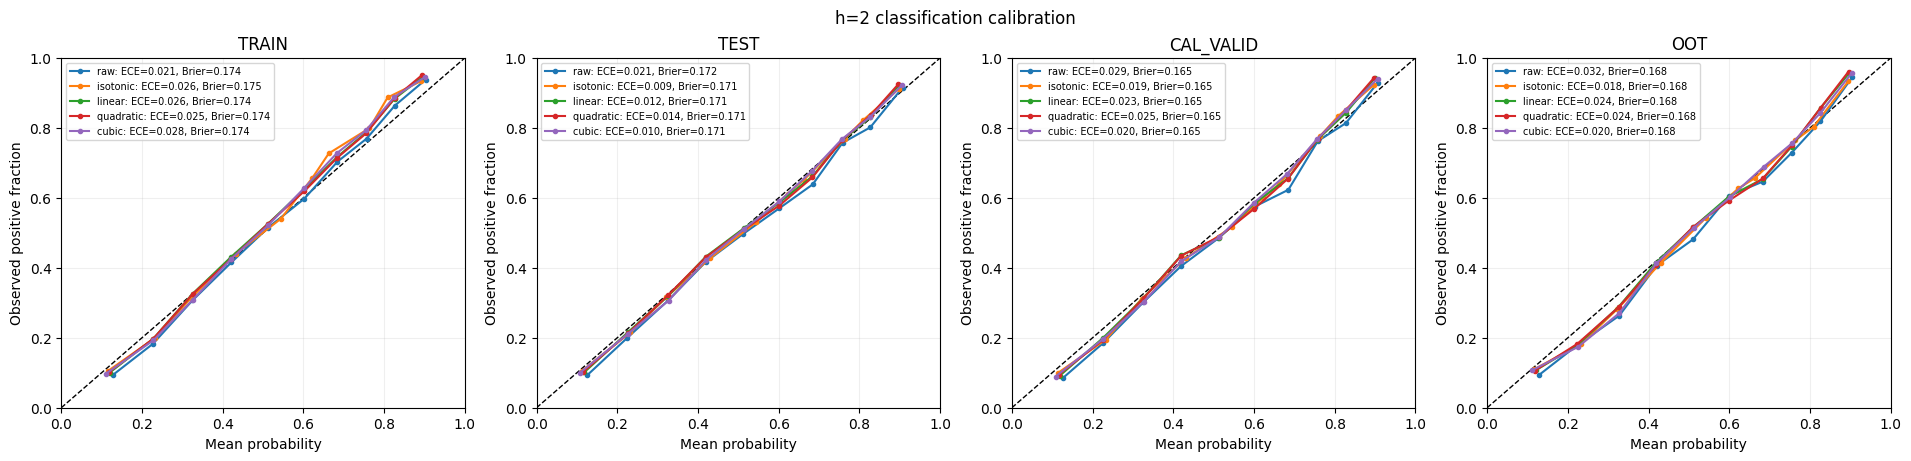

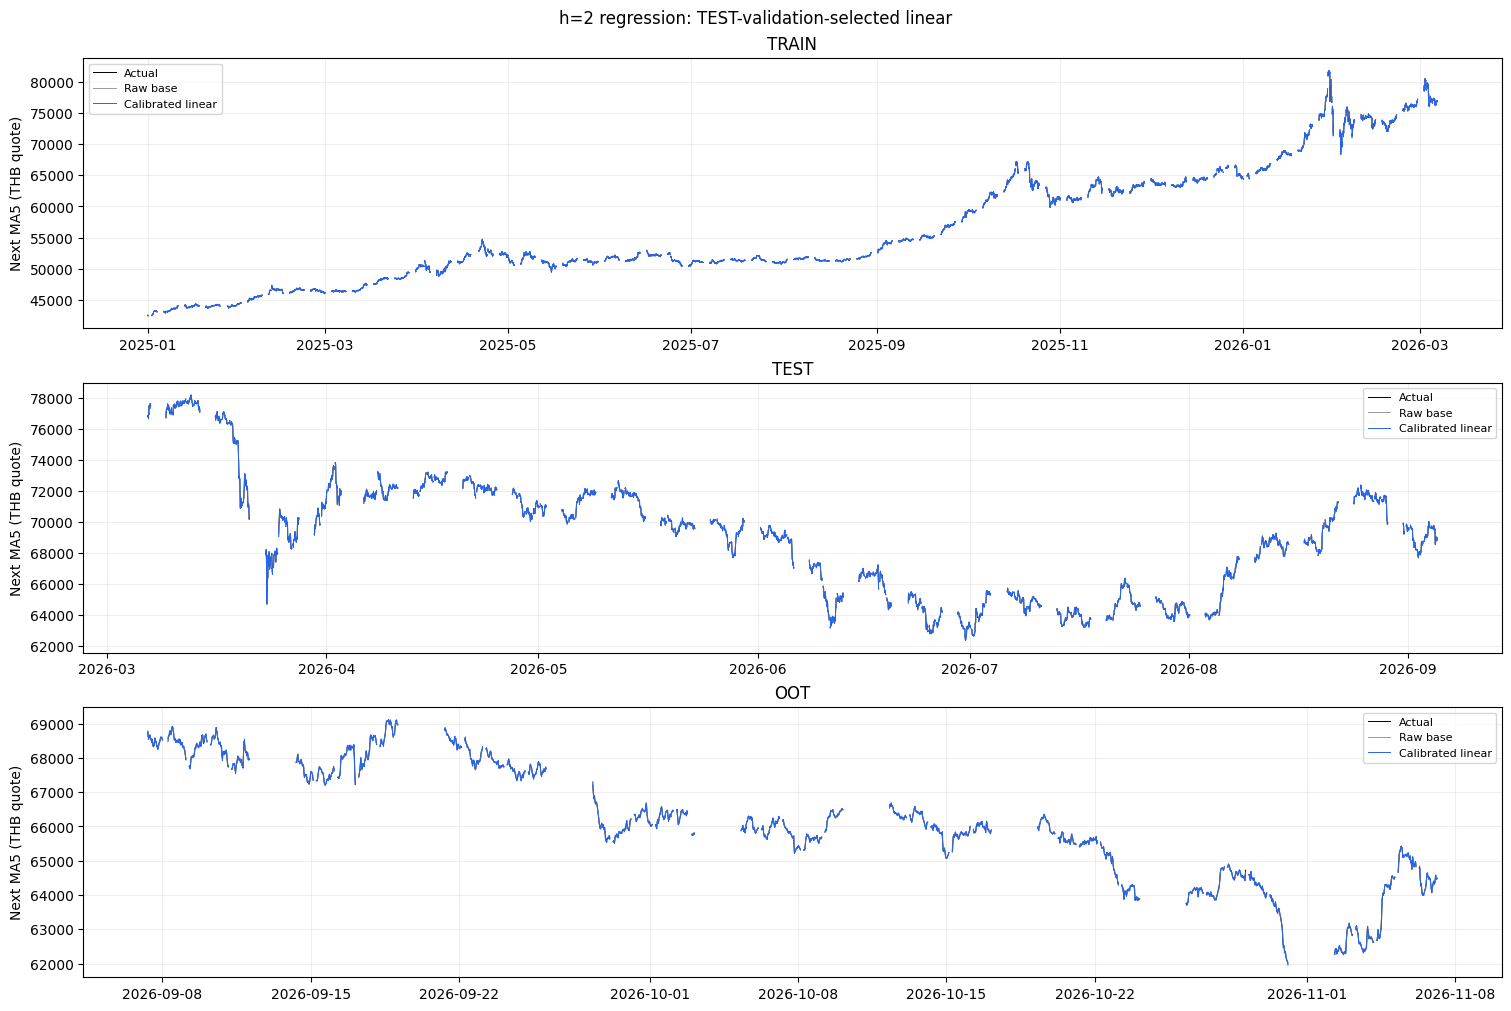

,horizon,task,partition,method,n,RMSE,MAE,Brier,ECE,accuracy,log_loss,outside_probability_range
60,2,regression,OOT,raw,3629,31.717114,23.061196,NaN,NaN,NaN,NaN,NaN
61,2,regression,OOT,isotonic,3629,745.214105,378.978419,NaN,NaN,NaN,NaN,NaN
62,2,regression,OOT,linear,3629,31.707481,23.068599,NaN,NaN,NaN,NaN,NaN
63,2,regression,OOT,quadratic,3629,33.497615,24.959513,NaN,NaN,NaN,NaN,NaN
64,2,regression,OOT,cubic,3629,47.287515,36.530012,NaN,NaN,NaN,NaN,NaN
65,2,regression,CAL_FIT,raw,5181,48.539118,31.422991,NaN,NaN,NaN,NaN,NaN
66,2,regression,CAL_FIT,isotonic,5181,41.793508,27.692514,NaN,NaN,NaN,NaN,NaN
67,2,regression,CAL_FIT,linear,5181,48.475040,31.394997,NaN,NaN,NaN,NaN,NaN
68,2,regression,CAL_FIT,quadratic,5181,48.445071,31.411093,NaN,NaN,NaN,NaN,NaN
69,2,regression,CAL_FIT,cubic,5181,48.411638,31.413230,NaN,NaN,NaN,NaN,NaN


In [3]:
h=2
# Fit only on earlier TEST labels. Numerical scaling uses CAL_FIT predictions only.
models={}; data={}; predictions={}
for task in ['regression','classification']:
    x={name:base_prediction(h,task,ix) for name,ix in sets.items()}
    y={name:D.loc[ix,f'y_h{h}'].to_numpy() if task=='regression' else (D.loc[ix,f'y_h{h}'].to_numpy()>D.ma5_current.iloc[ix].to_numpy()).astype(int) for name,ix in sets.items()}
    task_models={}
    for method,degree in [('isotonic',None),('linear',1),('quadratic',2),('cubic',3)]:
        model=IsotonicRegression(increasing=True,out_of_bounds='clip') if degree is None else make_pipeline(StandardScaler(),PolynomialFeatures(degree=degree,include_bias=False),LinearRegression())
        model.fit(x['CAL_FIT'] if degree is None else x['CAL_FIT'].reshape(-1,1),y['CAL_FIT'])
        task_models[method]=model
        with (P/f'h{h}_{task}_{method}.pkl').open('wb') as file: pickle.dump(model,file)
        if degree is None: detail={'X_thresholds':model.X_thresholds_.tolist(),'y_thresholds':model.y_thresholds_.tolist()}
        else:
            detail={'X_mean':model[0].mean_.tolist(),'X_scale':model[0].scale_.tolist(),'intercept':float(model[-1].intercept_),'coefficients_standardized_X_powers':model[-1].coef_.tolist()}
        parameters.append(dict(horizon=h,task=task,method=method,parameters=json.dumps(detail)))
    # Regression choice uses later TEST only; original is an explicit benchmark.
    if task=='regression':
        scores={method:float(np.sqrt(np.mean((y['CAL_VALID']-apply(model,method,x['CAL_VALID']))**2))) for method,model in task_models.items()}
        winner=min(scores,key=scores.get)
        selections.append(dict(horizon=h,selected_method=winner,validation_RMSE=scores[winner],raw_validation_RMSE=float(np.sqrt(np.mean((y['CAL_VALID']-x['CAL_VALID'])**2)))))
    edges=np.unique(np.quantile(x['TRAIN'],np.arange(.1,1,.1))) if task=='classification' else None
    for part in sets:
        for method in ['raw',*task_models]:
            raw=x[part] if method=='raw' else apply(task_models[method],method,x[part])
            pred=np.clip(raw,1e-6,1-1e-6) if task=='classification' else raw
            predictions[(task,part,method)]=pred
            if task=='regression':
                row=dict(RMSE=float(np.sqrt(np.mean((y[part]-pred)**2))),MAE=float(np.mean(abs(y[part]-pred))),Brier=np.nan,ECE=np.nan,accuracy=np.nan,log_loss=np.nan,outside_probability_range=np.nan)
            else:
                error,ds=ece(y[part],pred,edges)
                deciles.extend(dict(horizon=h,partition=part,method=method,**z) for z in ds)
                row=dict(RMSE=np.nan,MAE=np.nan,Brier=brier_score_loss(y[part],pred),ECE=error,accuracy=accuracy_score(y[part],pred>.5),log_loss=log_loss(y[part],pred),outside_probability_range=float(((raw<0)|(raw>1)).mean()))
            records.append(dict(horizon=h,task=task,partition=part,method=method,n=len(pred),**row))
    data[task]=(x,y);models[task]=task_models
# Reliability diagrams use fixed TRAIN raw-probability decile cutoffs for all methods/sets.
fig,axes=plt.subplots(1,4,figsize=(19,4.5),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','CAL_VALID','OOT']):
    ax.plot([0,1],[0,1],'k--',lw=1)
    for method in ['raw','isotonic','linear','quadratic','cubic']:
        z=pd.DataFrame(deciles);z=z[(z.horizon==h)&(z.partition==part)&(z.method==method)&(z.n>0)]
        score=next(r for r in records if r['horizon']==h and r['task']=='classification' and r['partition']==part and r['method']==method)
        ax.plot(z.mean_probability,z.observed_rate,'-o',ms=3,label=f"{method}: ECE={score['ECE']:.3f}, Brier={score['Brier']:.3f}")
    ax.set(title=part,xlim=(0,1),ylim=(0,1),xlabel='Mean probability',ylabel='Observed positive fraction');ax.legend(fontsize=7);ax.grid(alpha=.2)
fig.suptitle(f'h={h} classification calibration');fig.savefig(P/f'h{h}_classification.png',dpi=140);plt.show()
# All three requested sets plus the separate calibration fit/validation scores remain in the table.
fig,axes=plt.subplots(3,1,figsize=(15,10),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    ix=sets[part];dates=t.iloc[ix].dt.tz_convert('Asia/Bangkok').reset_index(drop=True)
    actual=D.loc[ix,f'y_h{h}'].to_numpy();raw=predictions[('regression',part,'raw')];chosen=predictions[('regression',part,winner)]
    segments=dates.diff().ne(pd.Timedelta(minutes=15)).cumsum()
    for j,(_,positions) in enumerate(pd.Series(np.arange(len(ix))).groupby(segments)):
        v=positions.to_numpy()
        for values,label,color in [(actual,'Actual','black'),(raw,'Raw base','#999999'),(chosen,f'Calibrated {winner}','#2563eb')]:
            ax.plot(dates.iloc[v],values[v],lw=.7,color=color,label=label if j==0 else None)
    ax.set(title=part,ylabel='Next MA5 (THB quote)');ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.suptitle(f'h={h} regression: TEST-validation-selected {winner}');fig.savefig(P/f'h{h}_regression.png',dpi=140);plt.show()
table=pd.DataFrame(records);display(table[(table.horizon==h)&table.partition.isin(['CAL_FIT','CAL_VALID','OOT'])])


**Interpretation:** compare CAL_VALID with CAL_FIT for fitting optimism, then inspect OOT. A smaller Brier/ECE indicates better probability reliability; calibration alone does not establish incremental forecast skill. For regression, compare the selected calibrator with the raw base model—forcing a winner among calibrators can still worsen RMSE.

## Horizon 3: 45 minutes
Key: four single-input mappings are fitted on CAL_FIT. Regression selection uses CAL_VALID RMSE. Classification retains every mapping; clipped polynomial probabilities and out-of-range rates must be reviewed. TRAIN curves use later-fitted calibration parameters retrospectively.

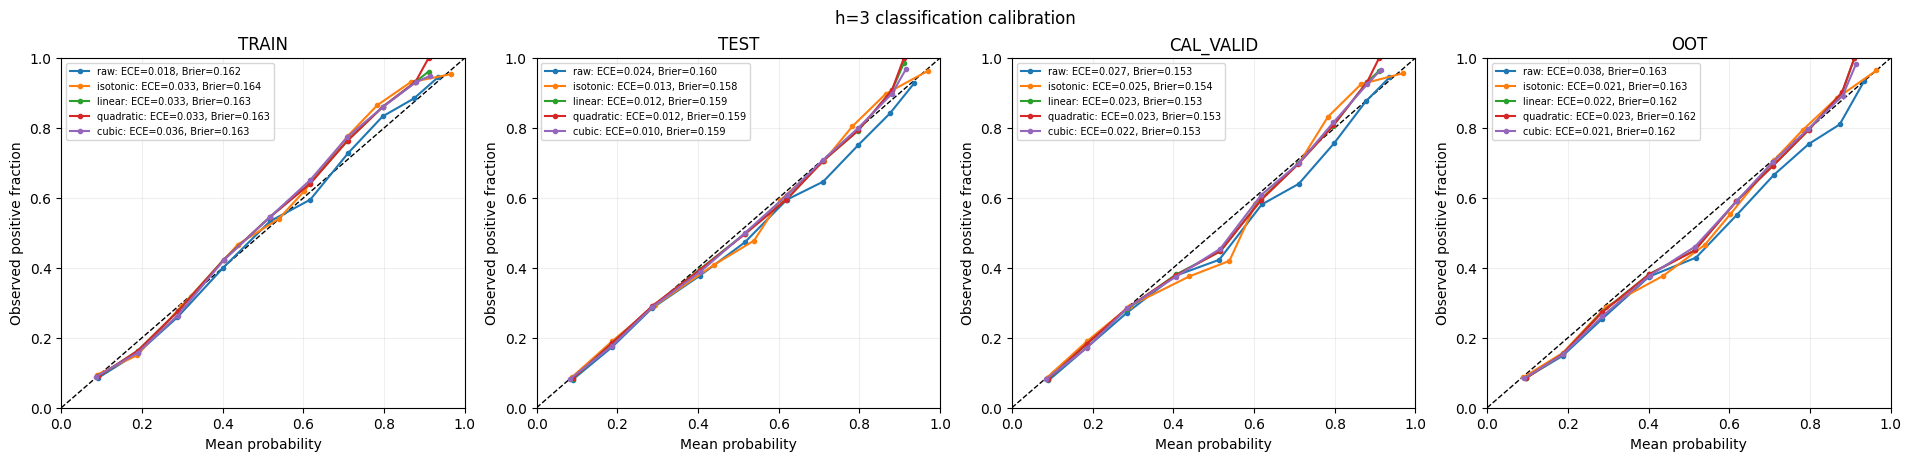

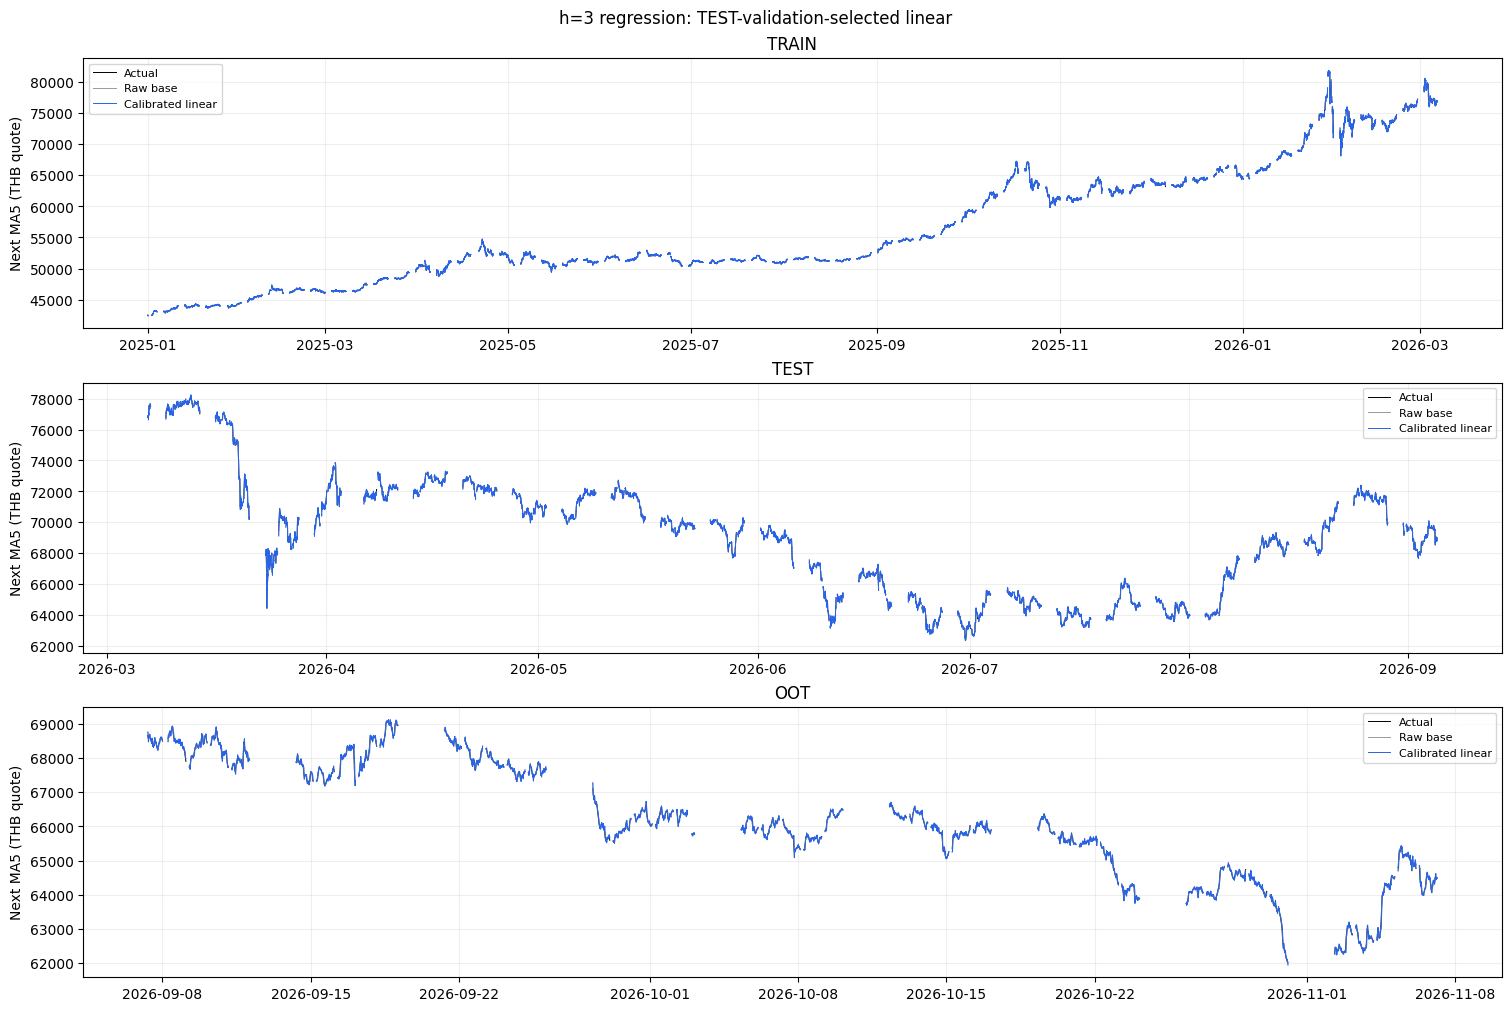

,horizon,task,partition,method,n,RMSE,MAE,Brier,ECE,accuracy,log_loss,outside_probability_range
110,3,regression,OOT,raw,3629,52.630836,38.323149,NaN,NaN,NaN,NaN,NaN
111,3,regression,OOT,isotonic,3629,771.352872,388.816689,NaN,NaN,NaN,NaN,NaN
112,3,regression,OOT,linear,3629,52.631064,38.367233,NaN,NaN,NaN,NaN,NaN
113,3,regression,OOT,quadratic,3629,57.429292,43.261493,NaN,NaN,NaN,NaN,NaN
114,3,regression,OOT,cubic,3629,87.768012,68.104152,NaN,NaN,NaN,NaN,NaN
115,3,regression,CAL_FIT,raw,5181,80.053425,51.928983,NaN,NaN,NaN,NaN,NaN
116,3,regression,CAL_FIT,isotonic,5181,70.270179,46.848534,NaN,NaN,NaN,NaN,NaN
117,3,regression,CAL_FIT,linear,5181,79.899846,51.849071,NaN,NaN,NaN,NaN,NaN
118,3,regression,CAL_FIT,quadratic,5181,79.818432,51.824571,NaN,NaN,NaN,NaN,NaN
119,3,regression,CAL_FIT,cubic,5181,79.738998,51.808997,NaN,NaN,NaN,NaN,NaN


In [4]:
h=3
# Fit only on earlier TEST labels. Numerical scaling uses CAL_FIT predictions only.
models={}; data={}; predictions={}
for task in ['regression','classification']:
    x={name:base_prediction(h,task,ix) for name,ix in sets.items()}
    y={name:D.loc[ix,f'y_h{h}'].to_numpy() if task=='regression' else (D.loc[ix,f'y_h{h}'].to_numpy()>D.ma5_current.iloc[ix].to_numpy()).astype(int) for name,ix in sets.items()}
    task_models={}
    for method,degree in [('isotonic',None),('linear',1),('quadratic',2),('cubic',3)]:
        model=IsotonicRegression(increasing=True,out_of_bounds='clip') if degree is None else make_pipeline(StandardScaler(),PolynomialFeatures(degree=degree,include_bias=False),LinearRegression())
        model.fit(x['CAL_FIT'] if degree is None else x['CAL_FIT'].reshape(-1,1),y['CAL_FIT'])
        task_models[method]=model
        with (P/f'h{h}_{task}_{method}.pkl').open('wb') as file: pickle.dump(model,file)
        if degree is None: detail={'X_thresholds':model.X_thresholds_.tolist(),'y_thresholds':model.y_thresholds_.tolist()}
        else:
            detail={'X_mean':model[0].mean_.tolist(),'X_scale':model[0].scale_.tolist(),'intercept':float(model[-1].intercept_),'coefficients_standardized_X_powers':model[-1].coef_.tolist()}
        parameters.append(dict(horizon=h,task=task,method=method,parameters=json.dumps(detail)))
    # Regression choice uses later TEST only; original is an explicit benchmark.
    if task=='regression':
        scores={method:float(np.sqrt(np.mean((y['CAL_VALID']-apply(model,method,x['CAL_VALID']))**2))) for method,model in task_models.items()}
        winner=min(scores,key=scores.get)
        selections.append(dict(horizon=h,selected_method=winner,validation_RMSE=scores[winner],raw_validation_RMSE=float(np.sqrt(np.mean((y['CAL_VALID']-x['CAL_VALID'])**2)))))
    edges=np.unique(np.quantile(x['TRAIN'],np.arange(.1,1,.1))) if task=='classification' else None
    for part in sets:
        for method in ['raw',*task_models]:
            raw=x[part] if method=='raw' else apply(task_models[method],method,x[part])
            pred=np.clip(raw,1e-6,1-1e-6) if task=='classification' else raw
            predictions[(task,part,method)]=pred
            if task=='regression':
                row=dict(RMSE=float(np.sqrt(np.mean((y[part]-pred)**2))),MAE=float(np.mean(abs(y[part]-pred))),Brier=np.nan,ECE=np.nan,accuracy=np.nan,log_loss=np.nan,outside_probability_range=np.nan)
            else:
                error,ds=ece(y[part],pred,edges)
                deciles.extend(dict(horizon=h,partition=part,method=method,**z) for z in ds)
                row=dict(RMSE=np.nan,MAE=np.nan,Brier=brier_score_loss(y[part],pred),ECE=error,accuracy=accuracy_score(y[part],pred>.5),log_loss=log_loss(y[part],pred),outside_probability_range=float(((raw<0)|(raw>1)).mean()))
            records.append(dict(horizon=h,task=task,partition=part,method=method,n=len(pred),**row))
    data[task]=(x,y);models[task]=task_models
# Reliability diagrams use fixed TRAIN raw-probability decile cutoffs for all methods/sets.
fig,axes=plt.subplots(1,4,figsize=(19,4.5),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','CAL_VALID','OOT']):
    ax.plot([0,1],[0,1],'k--',lw=1)
    for method in ['raw','isotonic','linear','quadratic','cubic']:
        z=pd.DataFrame(deciles);z=z[(z.horizon==h)&(z.partition==part)&(z.method==method)&(z.n>0)]
        score=next(r for r in records if r['horizon']==h and r['task']=='classification' and r['partition']==part and r['method']==method)
        ax.plot(z.mean_probability,z.observed_rate,'-o',ms=3,label=f"{method}: ECE={score['ECE']:.3f}, Brier={score['Brier']:.3f}")
    ax.set(title=part,xlim=(0,1),ylim=(0,1),xlabel='Mean probability',ylabel='Observed positive fraction');ax.legend(fontsize=7);ax.grid(alpha=.2)
fig.suptitle(f'h={h} classification calibration');fig.savefig(P/f'h{h}_classification.png',dpi=140);plt.show()
# All three requested sets plus the separate calibration fit/validation scores remain in the table.
fig,axes=plt.subplots(3,1,figsize=(15,10),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    ix=sets[part];dates=t.iloc[ix].dt.tz_convert('Asia/Bangkok').reset_index(drop=True)
    actual=D.loc[ix,f'y_h{h}'].to_numpy();raw=predictions[('regression',part,'raw')];chosen=predictions[('regression',part,winner)]
    segments=dates.diff().ne(pd.Timedelta(minutes=15)).cumsum()
    for j,(_,positions) in enumerate(pd.Series(np.arange(len(ix))).groupby(segments)):
        v=positions.to_numpy()
        for values,label,color in [(actual,'Actual','black'),(raw,'Raw base','#999999'),(chosen,f'Calibrated {winner}','#2563eb')]:
            ax.plot(dates.iloc[v],values[v],lw=.7,color=color,label=label if j==0 else None)
    ax.set(title=part,ylabel='Next MA5 (THB quote)');ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.suptitle(f'h={h} regression: TEST-validation-selected {winner}');fig.savefig(P/f'h{h}_regression.png',dpi=140);plt.show()
table=pd.DataFrame(records);display(table[(table.horizon==h)&table.partition.isin(['CAL_FIT','CAL_VALID','OOT'])])


**Interpretation:** compare CAL_VALID with CAL_FIT for fitting optimism, then inspect OOT. A smaller Brier/ECE indicates better probability reliability; calibration alone does not establish incremental forecast skill. For regression, compare the selected calibrator with the raw base model—forcing a winner among calibrators can still worsen RMSE.

## Horizon 4: 60 minutes
Key: four single-input mappings are fitted on CAL_FIT. Regression selection uses CAL_VALID RMSE. Classification retains every mapping; clipped polynomial probabilities and out-of-range rates must be reviewed. TRAIN curves use later-fitted calibration parameters retrospectively.

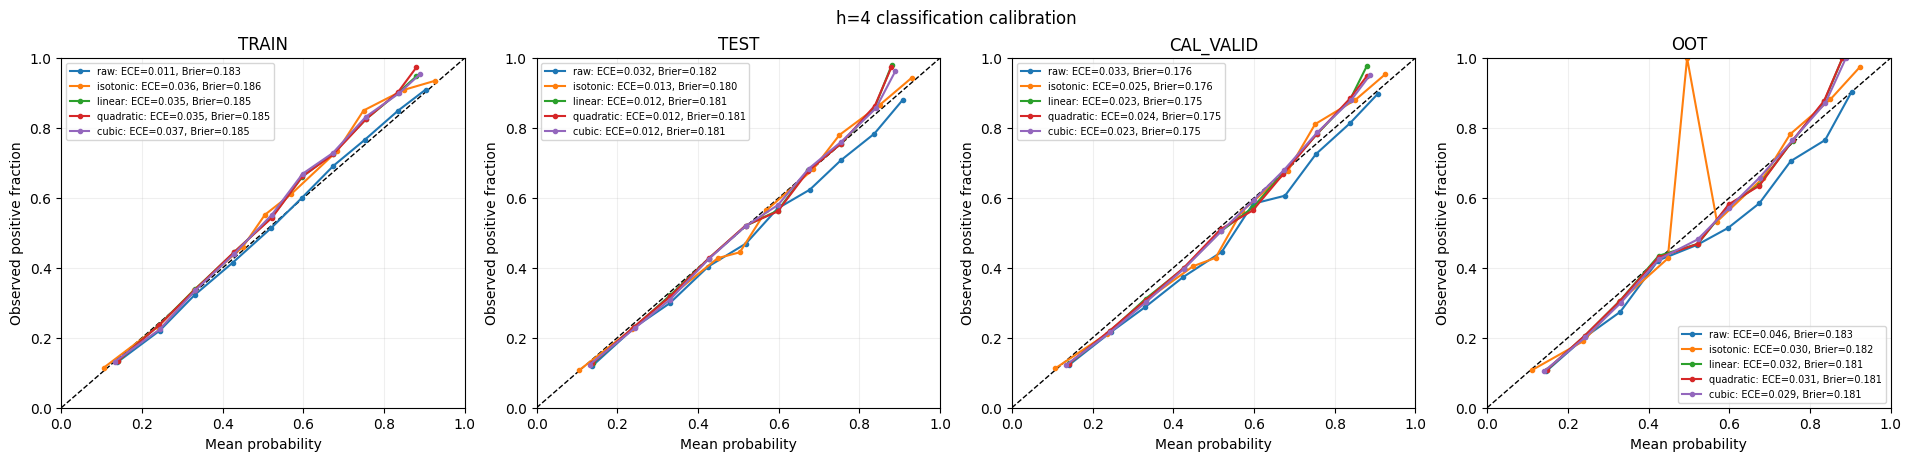

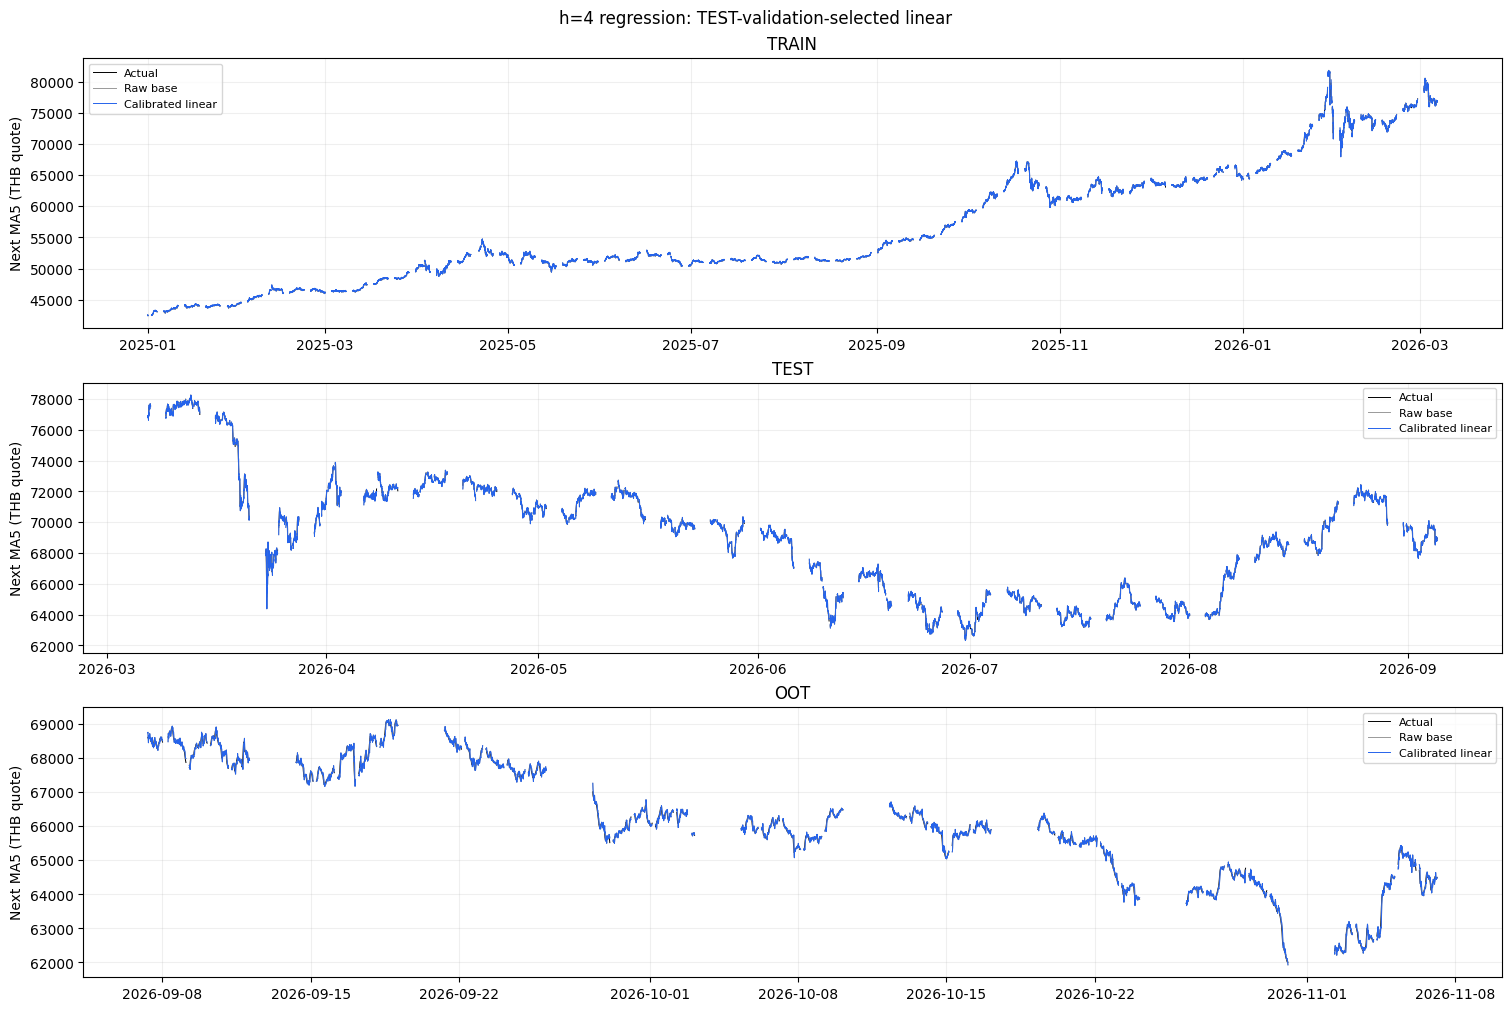

,horizon,task,partition,method,n,RMSE,MAE,Brier,ECE,accuracy,log_loss,outside_probability_range
160,4,regression,OOT,raw,3629,76.586504,55.701758,NaN,NaN,NaN,NaN,NaN
161,4,regression,OOT,isotonic,3629,801.421150,422.167224,NaN,NaN,NaN,NaN,NaN
162,4,regression,OOT,linear,3629,76.564780,55.742365,NaN,NaN,NaN,NaN,NaN
163,4,regression,OOT,quadratic,3629,85.885914,65.333310,NaN,NaN,NaN,NaN,NaN
164,4,regression,OOT,cubic,3629,138.795324,107.969851,NaN,NaN,NaN,NaN,NaN
165,4,regression,CAL_FIT,raw,5181,116.777299,75.242160,NaN,NaN,NaN,NaN,NaN
166,4,regression,CAL_FIT,isotonic,5181,104.066879,68.669818,NaN,NaN,NaN,NaN,NaN
167,4,regression,CAL_FIT,linear,5181,116.473820,75.107730,NaN,NaN,NaN,NaN,NaN
168,4,regression,CAL_FIT,quadratic,5181,116.308944,75.007875,NaN,NaN,NaN,NaN,NaN
169,4,regression,CAL_FIT,cubic,5181,116.161604,75.037222,NaN,NaN,NaN,NaN,NaN


In [5]:
h=4
# Fit only on earlier TEST labels. Numerical scaling uses CAL_FIT predictions only.
models={}; data={}; predictions={}
for task in ['regression','classification']:
    x={name:base_prediction(h,task,ix) for name,ix in sets.items()}
    y={name:D.loc[ix,f'y_h{h}'].to_numpy() if task=='regression' else (D.loc[ix,f'y_h{h}'].to_numpy()>D.ma5_current.iloc[ix].to_numpy()).astype(int) for name,ix in sets.items()}
    task_models={}
    for method,degree in [('isotonic',None),('linear',1),('quadratic',2),('cubic',3)]:
        model=IsotonicRegression(increasing=True,out_of_bounds='clip') if degree is None else make_pipeline(StandardScaler(),PolynomialFeatures(degree=degree,include_bias=False),LinearRegression())
        model.fit(x['CAL_FIT'] if degree is None else x['CAL_FIT'].reshape(-1,1),y['CAL_FIT'])
        task_models[method]=model
        with (P/f'h{h}_{task}_{method}.pkl').open('wb') as file: pickle.dump(model,file)
        if degree is None: detail={'X_thresholds':model.X_thresholds_.tolist(),'y_thresholds':model.y_thresholds_.tolist()}
        else:
            detail={'X_mean':model[0].mean_.tolist(),'X_scale':model[0].scale_.tolist(),'intercept':float(model[-1].intercept_),'coefficients_standardized_X_powers':model[-1].coef_.tolist()}
        parameters.append(dict(horizon=h,task=task,method=method,parameters=json.dumps(detail)))
    # Regression choice uses later TEST only; original is an explicit benchmark.
    if task=='regression':
        scores={method:float(np.sqrt(np.mean((y['CAL_VALID']-apply(model,method,x['CAL_VALID']))**2))) for method,model in task_models.items()}
        winner=min(scores,key=scores.get)
        selections.append(dict(horizon=h,selected_method=winner,validation_RMSE=scores[winner],raw_validation_RMSE=float(np.sqrt(np.mean((y['CAL_VALID']-x['CAL_VALID'])**2)))))
    edges=np.unique(np.quantile(x['TRAIN'],np.arange(.1,1,.1))) if task=='classification' else None
    for part in sets:
        for method in ['raw',*task_models]:
            raw=x[part] if method=='raw' else apply(task_models[method],method,x[part])
            pred=np.clip(raw,1e-6,1-1e-6) if task=='classification' else raw
            predictions[(task,part,method)]=pred
            if task=='regression':
                row=dict(RMSE=float(np.sqrt(np.mean((y[part]-pred)**2))),MAE=float(np.mean(abs(y[part]-pred))),Brier=np.nan,ECE=np.nan,accuracy=np.nan,log_loss=np.nan,outside_probability_range=np.nan)
            else:
                error,ds=ece(y[part],pred,edges)
                deciles.extend(dict(horizon=h,partition=part,method=method,**z) for z in ds)
                row=dict(RMSE=np.nan,MAE=np.nan,Brier=brier_score_loss(y[part],pred),ECE=error,accuracy=accuracy_score(y[part],pred>.5),log_loss=log_loss(y[part],pred),outside_probability_range=float(((raw<0)|(raw>1)).mean()))
            records.append(dict(horizon=h,task=task,partition=part,method=method,n=len(pred),**row))
    data[task]=(x,y);models[task]=task_models
# Reliability diagrams use fixed TRAIN raw-probability decile cutoffs for all methods/sets.
fig,axes=plt.subplots(1,4,figsize=(19,4.5),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','CAL_VALID','OOT']):
    ax.plot([0,1],[0,1],'k--',lw=1)
    for method in ['raw','isotonic','linear','quadratic','cubic']:
        z=pd.DataFrame(deciles);z=z[(z.horizon==h)&(z.partition==part)&(z.method==method)&(z.n>0)]
        score=next(r for r in records if r['horizon']==h and r['task']=='classification' and r['partition']==part and r['method']==method)
        ax.plot(z.mean_probability,z.observed_rate,'-o',ms=3,label=f"{method}: ECE={score['ECE']:.3f}, Brier={score['Brier']:.3f}")
    ax.set(title=part,xlim=(0,1),ylim=(0,1),xlabel='Mean probability',ylabel='Observed positive fraction');ax.legend(fontsize=7);ax.grid(alpha=.2)
fig.suptitle(f'h={h} classification calibration');fig.savefig(P/f'h{h}_classification.png',dpi=140);plt.show()
# All three requested sets plus the separate calibration fit/validation scores remain in the table.
fig,axes=plt.subplots(3,1,figsize=(15,10),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    ix=sets[part];dates=t.iloc[ix].dt.tz_convert('Asia/Bangkok').reset_index(drop=True)
    actual=D.loc[ix,f'y_h{h}'].to_numpy();raw=predictions[('regression',part,'raw')];chosen=predictions[('regression',part,winner)]
    segments=dates.diff().ne(pd.Timedelta(minutes=15)).cumsum()
    for j,(_,positions) in enumerate(pd.Series(np.arange(len(ix))).groupby(segments)):
        v=positions.to_numpy()
        for values,label,color in [(actual,'Actual','black'),(raw,'Raw base','#999999'),(chosen,f'Calibrated {winner}','#2563eb')]:
            ax.plot(dates.iloc[v],values[v],lw=.7,color=color,label=label if j==0 else None)
    ax.set(title=part,ylabel='Next MA5 (THB quote)');ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.suptitle(f'h={h} regression: TEST-validation-selected {winner}');fig.savefig(P/f'h{h}_regression.png',dpi=140);plt.show()
table=pd.DataFrame(records);display(table[(table.horizon==h)&table.partition.isin(['CAL_FIT','CAL_VALID','OOT'])])


**Interpretation:** compare CAL_VALID with CAL_FIT for fitting optimism, then inspect OOT. A smaller Brier/ECE indicates better probability reliability; calibration alone does not establish incremental forecast skill. For regression, compare the selected calibrator with the raw base model—forcing a winner among calibrators can still worsen RMSE.

## Horizon 5: 75 minutes
Key: four single-input mappings are fitted on CAL_FIT. Regression selection uses CAL_VALID RMSE. Classification retains every mapping; clipped polynomial probabilities and out-of-range rates must be reviewed. TRAIN curves use later-fitted calibration parameters retrospectively.

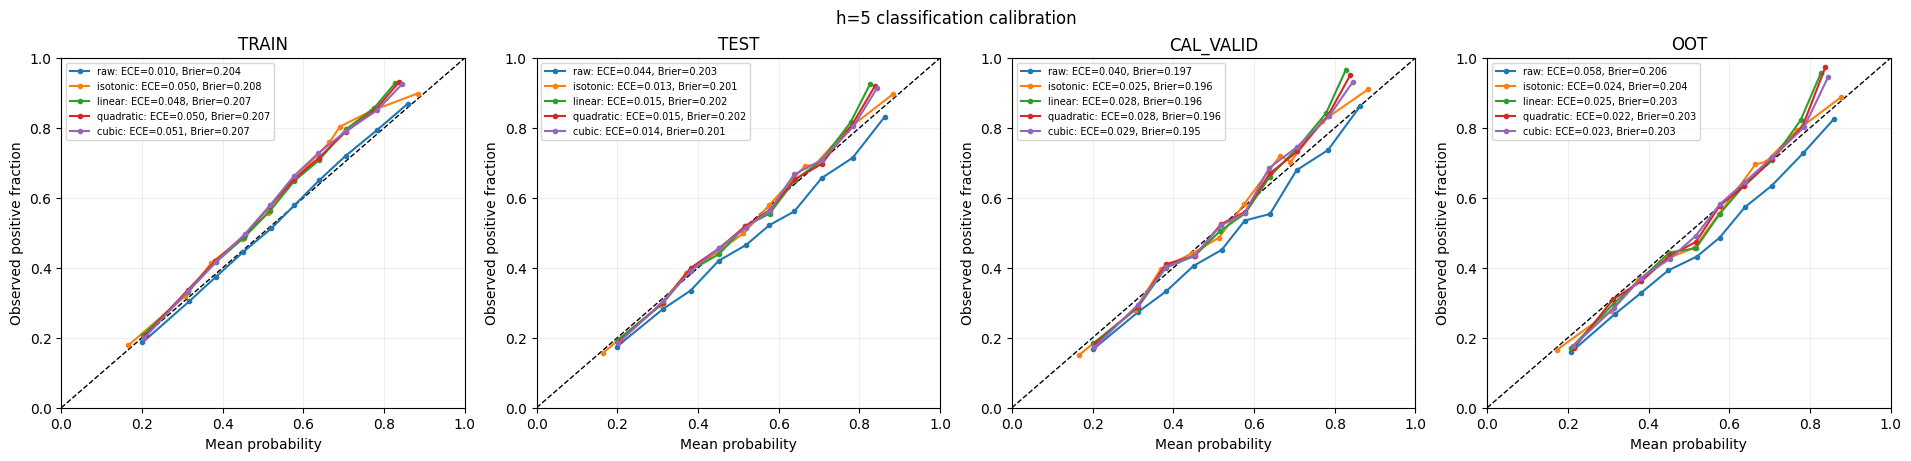

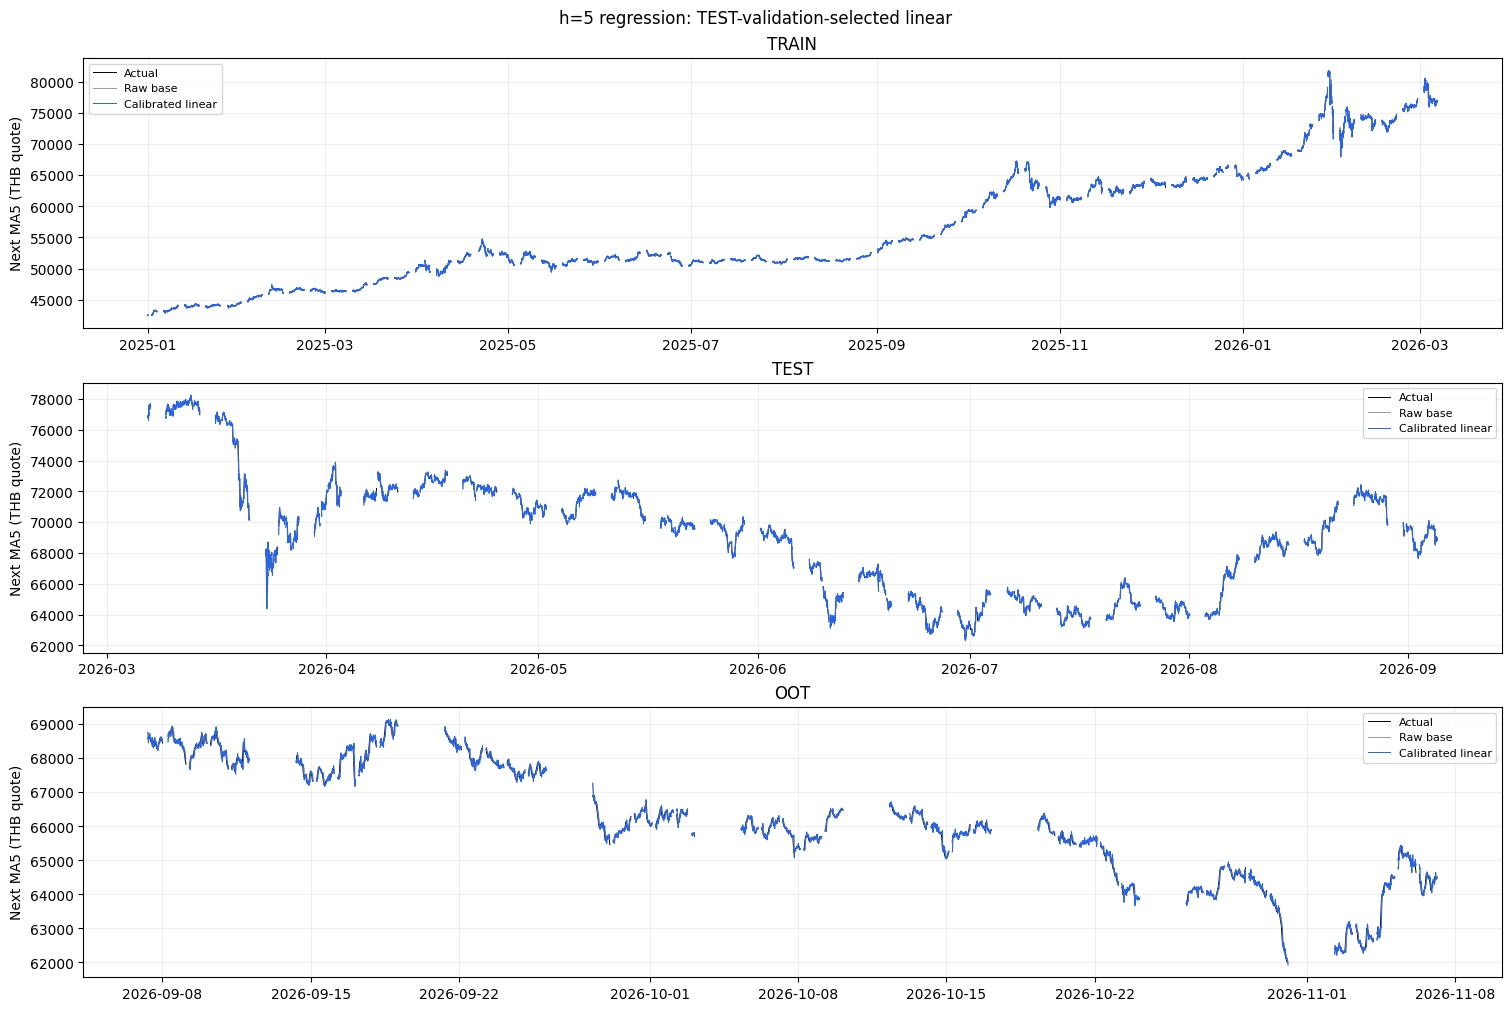

,horizon,task,partition,method,n,RMSE,MAE,Brier,ECE,accuracy,log_loss,outside_probability_range
210,5,regression,OOT,raw,3629,103.121540,74.978483,NaN,NaN,NaN,NaN,NaN
211,5,regression,OOT,isotonic,3629,937.104070,535.302292,NaN,NaN,NaN,NaN,NaN
212,5,regression,OOT,linear,3629,103.103516,75.038113,NaN,NaN,NaN,NaN,NaN
213,5,regression,OOT,quadratic,3629,119.528205,91.886781,NaN,NaN,NaN,NaN,NaN
214,5,regression,OOT,cubic,3629,199.490408,155.592175,NaN,NaN,NaN,NaN,NaN
215,5,regression,CAL_FIT,raw,5181,157.725824,101.371259,NaN,NaN,NaN,NaN,NaN
216,5,regression,CAL_FIT,isotonic,5181,141.746616,93.008398,NaN,NaN,NaN,NaN,NaN
217,5,regression,CAL_FIT,linear,5181,157.204866,101.073650,NaN,NaN,NaN,NaN,NaN
218,5,regression,CAL_FIT,quadratic,5181,156.907513,100.905281,NaN,NaN,NaN,NaN,NaN
219,5,regression,CAL_FIT,cubic,5181,156.682034,100.929207,NaN,NaN,NaN,NaN,NaN


In [6]:
h=5
# Fit only on earlier TEST labels. Numerical scaling uses CAL_FIT predictions only.
models={}; data={}; predictions={}
for task in ['regression','classification']:
    x={name:base_prediction(h,task,ix) for name,ix in sets.items()}
    y={name:D.loc[ix,f'y_h{h}'].to_numpy() if task=='regression' else (D.loc[ix,f'y_h{h}'].to_numpy()>D.ma5_current.iloc[ix].to_numpy()).astype(int) for name,ix in sets.items()}
    task_models={}
    for method,degree in [('isotonic',None),('linear',1),('quadratic',2),('cubic',3)]:
        model=IsotonicRegression(increasing=True,out_of_bounds='clip') if degree is None else make_pipeline(StandardScaler(),PolynomialFeatures(degree=degree,include_bias=False),LinearRegression())
        model.fit(x['CAL_FIT'] if degree is None else x['CAL_FIT'].reshape(-1,1),y['CAL_FIT'])
        task_models[method]=model
        with (P/f'h{h}_{task}_{method}.pkl').open('wb') as file: pickle.dump(model,file)
        if degree is None: detail={'X_thresholds':model.X_thresholds_.tolist(),'y_thresholds':model.y_thresholds_.tolist()}
        else:
            detail={'X_mean':model[0].mean_.tolist(),'X_scale':model[0].scale_.tolist(),'intercept':float(model[-1].intercept_),'coefficients_standardized_X_powers':model[-1].coef_.tolist()}
        parameters.append(dict(horizon=h,task=task,method=method,parameters=json.dumps(detail)))
    # Regression choice uses later TEST only; original is an explicit benchmark.
    if task=='regression':
        scores={method:float(np.sqrt(np.mean((y['CAL_VALID']-apply(model,method,x['CAL_VALID']))**2))) for method,model in task_models.items()}
        winner=min(scores,key=scores.get)
        selections.append(dict(horizon=h,selected_method=winner,validation_RMSE=scores[winner],raw_validation_RMSE=float(np.sqrt(np.mean((y['CAL_VALID']-x['CAL_VALID'])**2)))))
    edges=np.unique(np.quantile(x['TRAIN'],np.arange(.1,1,.1))) if task=='classification' else None
    for part in sets:
        for method in ['raw',*task_models]:
            raw=x[part] if method=='raw' else apply(task_models[method],method,x[part])
            pred=np.clip(raw,1e-6,1-1e-6) if task=='classification' else raw
            predictions[(task,part,method)]=pred
            if task=='regression':
                row=dict(RMSE=float(np.sqrt(np.mean((y[part]-pred)**2))),MAE=float(np.mean(abs(y[part]-pred))),Brier=np.nan,ECE=np.nan,accuracy=np.nan,log_loss=np.nan,outside_probability_range=np.nan)
            else:
                error,ds=ece(y[part],pred,edges)
                deciles.extend(dict(horizon=h,partition=part,method=method,**z) for z in ds)
                row=dict(RMSE=np.nan,MAE=np.nan,Brier=brier_score_loss(y[part],pred),ECE=error,accuracy=accuracy_score(y[part],pred>.5),log_loss=log_loss(y[part],pred),outside_probability_range=float(((raw<0)|(raw>1)).mean()))
            records.append(dict(horizon=h,task=task,partition=part,method=method,n=len(pred),**row))
    data[task]=(x,y);models[task]=task_models
# Reliability diagrams use fixed TRAIN raw-probability decile cutoffs for all methods/sets.
fig,axes=plt.subplots(1,4,figsize=(19,4.5),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','CAL_VALID','OOT']):
    ax.plot([0,1],[0,1],'k--',lw=1)
    for method in ['raw','isotonic','linear','quadratic','cubic']:
        z=pd.DataFrame(deciles);z=z[(z.horizon==h)&(z.partition==part)&(z.method==method)&(z.n>0)]
        score=next(r for r in records if r['horizon']==h and r['task']=='classification' and r['partition']==part and r['method']==method)
        ax.plot(z.mean_probability,z.observed_rate,'-o',ms=3,label=f"{method}: ECE={score['ECE']:.3f}, Brier={score['Brier']:.3f}")
    ax.set(title=part,xlim=(0,1),ylim=(0,1),xlabel='Mean probability',ylabel='Observed positive fraction');ax.legend(fontsize=7);ax.grid(alpha=.2)
fig.suptitle(f'h={h} classification calibration');fig.savefig(P/f'h{h}_classification.png',dpi=140);plt.show()
# All three requested sets plus the separate calibration fit/validation scores remain in the table.
fig,axes=plt.subplots(3,1,figsize=(15,10),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    ix=sets[part];dates=t.iloc[ix].dt.tz_convert('Asia/Bangkok').reset_index(drop=True)
    actual=D.loc[ix,f'y_h{h}'].to_numpy();raw=predictions[('regression',part,'raw')];chosen=predictions[('regression',part,winner)]
    segments=dates.diff().ne(pd.Timedelta(minutes=15)).cumsum()
    for j,(_,positions) in enumerate(pd.Series(np.arange(len(ix))).groupby(segments)):
        v=positions.to_numpy()
        for values,label,color in [(actual,'Actual','black'),(raw,'Raw base','#999999'),(chosen,f'Calibrated {winner}','#2563eb')]:
            ax.plot(dates.iloc[v],values[v],lw=.7,color=color,label=label if j==0 else None)
    ax.set(title=part,ylabel='Next MA5 (THB quote)');ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.suptitle(f'h={h} regression: TEST-validation-selected {winner}');fig.savefig(P/f'h{h}_regression.png',dpi=140);plt.show()
table=pd.DataFrame(records);display(table[(table.horizon==h)&table.partition.isin(['CAL_FIT','CAL_VALID','OOT'])])


**Interpretation:** compare CAL_VALID with CAL_FIT for fitting optimism, then inspect OOT. A smaller Brier/ECE indicates better probability reliability; calibration alone does not establish incremental forecast skill. For regression, compare the selected calibrator with the raw base model—forcing a winner among calibrators can still worsen RMSE.

## Export results and selection
Key: classification keeps all four calibrators. Regression selects one per horizon by later TEST RMSE. A selected calibrator is not automatically better than the raw model. Metrics are descriptive on previously inspected history.

In [7]:
metrics=pd.DataFrame(records);selection=pd.DataFrame(selections)
metrics.to_csv(P/'metrics.csv',index=False)
selection.to_csv(P/'regression_selection.csv',index=False)
pd.DataFrame(parameters).to_csv(P/'calibrator_parameters.csv',index=False)
pd.DataFrame(deciles).to_csv(P/'classification_deciles.csv',index=False)
assert len(metrics)==250 and len(selection)==5
assert np.isfinite(metrics.loc[metrics.task.eq('classification'),'Brier']).all()
display(selection)
display(metrics.query('partition=="OOT"'))

,horizon,selected_method,validation_RMSE,raw_validation_RMSE
0,1,linear,17.439757,17.444823
1,2,linear,38.443555,38.452504
2,3,linear,63.900696,63.911102
3,4,linear,92.999825,93.034553
4,5,linear,125.871056,125.920229


,horizon,task,partition,method,n,RMSE,MAE,Brier,ECE,accuracy,log_loss,outside_probability_range
10,1,regression,OOT,raw,3629,14.641214,10.536154,NaN,NaN,NaN,NaN,NaN
11,1,regression,OOT,isotonic,3629,729.585807,333.797528,NaN,NaN,NaN,NaN,NaN
12,1,regression,OOT,linear,3629,14.633771,10.535455,NaN,NaN,NaN,NaN,NaN
13,1,regression,OOT,quadratic,3629,15.083488,11.054050,NaN,NaN,NaN,NaN,NaN
14,1,regression,OOT,cubic,3629,19.497329,14.882304,NaN,NaN,NaN,NaN,NaN
35,1,classification,OOT,raw,3629,NaN,NaN,0.131576,0.020451,0.817029,0.412839,0.000000
36,1,classification,OOT,isotonic,3629,NaN,NaN,0.132714,0.017221,0.817856,0.413744,0.000000
37,1,classification,OOT,linear,3629,NaN,NaN,0.131468,0.017980,0.818407,0.414965,0.000000
38,1,classification,OOT,quadratic,3629,NaN,NaN,0.131499,0.018316,0.817856,0.415048,0.000000
39,1,classification,OOT,cubic,3629,NaN,NaN,0.131675,0.020721,0.818132,0.412765,0.000276
